# Gom Cụm Các Bản Nhạc MP3 (Music Clustering)

**Sinh viên:** Phạm Tấn Đạt (`079206008013`)

## 1. Kiến trúc giải pháp đề xuất
1. **Tiền xử lý âm thanh:** Đọc tệp MP3/WAV bằng `librosa` (chuẩn hóa `sr=22050 Hz`, `mono`), cắt khoảng lặng đầu/cuối.
2. **Trích xuất đặc trưng (Feature Extraction):**
   - **Nhịp điệu & Năng lượng:** `Tempo (BPM)`, `RMS Energy`, `Zero-Crossing Rate (ZCR)`.
   - **Phổ tần (Spectral):** `Spectral Centroid`, `Bandwidth`, `Rolloff`, `Contrast`.
   - **Hòa âm & Âm sắc:** `Chroma STFT` (12 bậc cao độ) và `MFCC` (13 hệ số, mean & std).
3. **Chuẩn hóa & Giảm chiều:** `StandardScaler` + `PCA` (2D để trực quan hóa).
4. **Gom cụm không giám sát:** `K-Means` (tối ưu $k$ qua Elbow & Silhouette), `Agglomerative Clustering`, hoặc `DBSCAN`.
5. **Đánh giá & Xuất kết quả:** `Silhouette Score`, `Davies-Bouldin Index`, phân loại vào thư mục & playlist `.m3u8`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf

from music_clusterer import (
    scan_audio_files,
    extract_features_batch,
    evaluate_k_range,
    cluster_tracks,
    export_clusters_to_folders,
)

sns.set_theme(style="whitegrid")

## 2. Chuẩn bị dữ liệu âm thanh
Đặt các tệp `.mp3` của bạn vào thư mục `sample_music/`. Nếu thư mục chưa có nhạc, ô dưới đây sẽ tự tạo 9 bản nhạc tổng hợp thuộc 3 phong cách âm thanh khác nhau (Êm dịu/Trầm, Nhịp vừa/Hài hòa, Sôi động/Sáng) để kiểm thử pipeline.

In [2]:
music_dir = Path("sample_music")
music_dir.mkdir(exist_ok=True)
audio_files = scan_audio_files(str(music_dir))

if len(audio_files) == 0:
    sr = 22050
    t = np.linspace(0, 6.0, int(sr * 6.0), endpoint=False)
    rng = np.random.default_rng(42)

    # Nhóm 1: Nhạc trầm êm dịu (tần số thấp, tempo chậm)
    for i in range(1, 4):
        freq = 180 + i * 25
        env = 0.25 * (0.6 + 0.4 * np.sin(2 * np.pi * 1.1 * t))
        y = env * np.sin(2 * np.pi * freq * t)
        sf.write(music_dir / f"ambient_calm_{i}.wav", y, sr)

    # Nhóm 2: Nhạc nhịp vừa hài hòa (hợp âm + beat 110 BPM)
    for i in range(1, 4):
        f0 = 330 + i * 30
        beat = 0.5 + 0.5 * np.maximum(0, np.sin(2 * np.pi * (110 / 60) * t))
        y = 0.35 * beat * (np.sin(2 * np.pi * f0 * t) + 0.5 * np.sin(2 * np.pi * 1.5 * f0 * t))
        sf.write(music_dir / f"pop_groove_{i}.wav", y, sr)

    # Nhóm 3: Nhạc sôi động sáng (tần số cao + percussion noise, 145 BPM)
    for i in range(1, 4):
        f0 = 700 + i * 90
        pulse = (np.sin(2 * np.pi * (145 / 60) * t) > 0).astype(float)
        y = 0.45 * pulse * (np.sin(2 * np.pi * f0 * t) + 0.25 * rng.standard_normal(len(t)))
        sf.write(music_dir / f"edm_bright_{i}.wav", y, sr)

    audio_files = scan_audio_files(str(music_dir))

print(f"Tìm thấy {len(audio_files)} tệp âm thanh:")
for p in audio_files:
    print(" -", p.name)

Tìm thấy 9 tệp âm thanh:
 - ambient_calm_1.mp3
 - ambient_calm_2.mp3
 - ambient_calm_3.mp3
 - edm_bright_1.mp3
 - edm_bright_2.mp3
 - edm_bright_3.mp3
 - pop_groove_1.mp3
 - pop_groove_2.mp3
 - pop_groove_3.mp3


## 3. Trích xuất đặc trưng âm thanh

In [3]:
df_features, errors = extract_features_batch(audio_files, duration=30.0)
print(f"Trích xuất thành công: {len(df_features)} bài | Lỗi: {len(errors)}")
df_features[["filename", "duration_sec", "tempo_bpm", "rms_mean", "spectral_centroid_mean"]].head(10)

Trích xuất thành công: 9 bài | Lỗi: 0


,filename,duration_sec,tempo_bpm,rms_mean,spectral_centroid_mean
0,ambient_calm_1.mp3,5.0,123.05,0.110208,206.295319
1,ambient_calm_2.mp3,5.0,129.20,0.110417,232.330994
2,ambient_calm_3.mp3,5.0,123.05,0.110187,259.358368
3,edm_bright_1.mp3,5.0,143.55,0.193596,3933.745117
4,edm_bright_2.mp3,5.0,143.55,0.193339,3853.757812
5,edm_bright_3.mp3,5.0,143.55,0.196054,3865.241699
6,pop_groove_1.mp3,5.0,112.35,0.182849,420.926208
7,pop_groove_2.mp3,5.0,112.35,0.183155,457.982697
8,pop_groove_3.mp3,5.0,117.45,0.183171,494.786591


## 4. Tìm số cụm tối ưu (Elbow & Silhouette)

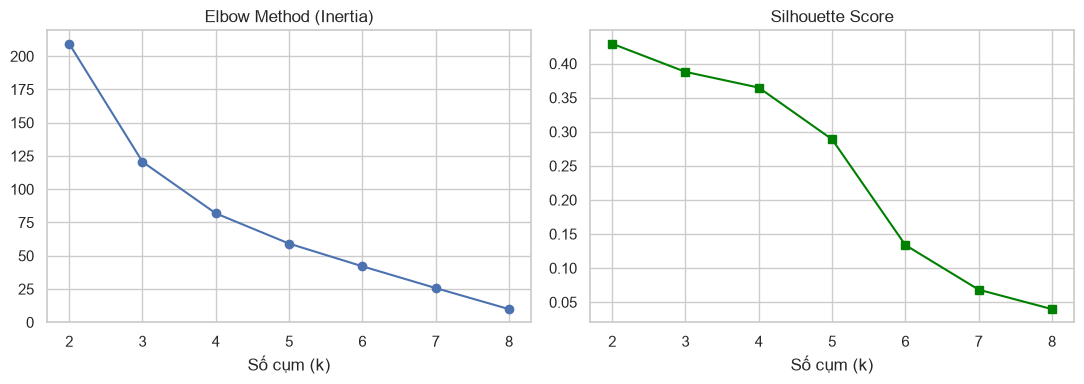

In [4]:
k_eval = evaluate_k_range(df_features, k_min=2, k_max=min(8, len(df_features) - 1))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(k_eval["k"], k_eval["inertia"], marker="o")
ax1.set_title("Elbow Method (Inertia)")
ax1.set_xlabel("Số cụm (k)")

ax2.plot(k_eval["k"], k_eval["silhouette"], marker="s", color="green")
ax2.set_title("Silhouette Score")
ax2.set_xlabel("Số cụm (k)")
plt.tight_layout()
plt.show()

## 5. Gom cụm K-Means & Trực quan hóa PCA 2D

Chỉ số đánh giá: {'silhouette': 0.3878628679874661, 'davies_bouldin': 0.8800123616256049, 'calinski_harabasz': 8.418544765609592, 'n_clusters_found': 3.0, 'n_noise': 0.0}


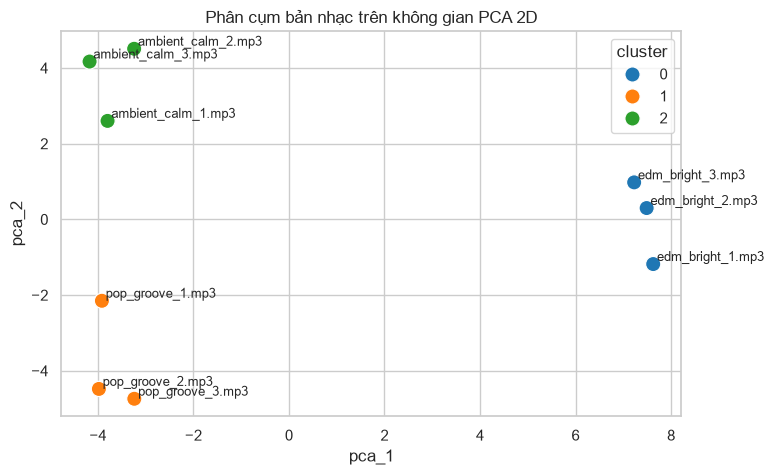

,cluster,tempo_bpm,rms_mean,zcr_mean,spectral_centroid_mean,spectral_bandwidth_mean,duration_sec,track_count,profile
0,0,143.55,0.194,0.146,3884.248,2752.848,5.0,3,Nhịp nhanh • Năng lượng cao • Âm sắc sáng
1,1,114.05,0.183,0.035,457.898,119.831,5.0,3,Nhịp chậm • Âm sắc trầm/ấm
2,2,125.10,0.110,0.021,232.662,64.214,5.0,3,Nhịp vừa • Êm dịu • Âm sắc trầm/ấm


In [5]:
res = cluster_tracks(df_features, algorithm="kmeans", n_clusters=3)
print("Chỉ số đánh giá:", res.metrics)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=res.df, x="pca_1", y="pca_2", hue="cluster", palette="tab10", s=120)
for _, row in res.df.iterrows():
    plt.text(row["pca_1"] + 0.08, row["pca_2"] + 0.08, row["filename"], fontsize=9)
plt.title("Phân cụm bản nhạc trên không gian PCA 2D")
plt.show()

res.cluster_profiles

## 6. Xuất kết quả theo cụm (Thư mục + Playlist .m3u8 + CSV)

In [6]:
out_dir = export_clusters_to_folders(res.df, "clustered_output", copy_files=True)
print(f"Đã xuất kết quả tại: {out_dir.resolve()}")

Đã xuất kết quả tại: E:\New folder (2)\New folder (2)\clustered_output
